# Anomaly Detection for Spacecraft Telemetry

## Introduction

Modern spacecraft continuously generate large volumes of **telemetry data** that describe the state of onboard subsystems and instruments. Monitoring this data is essential for ensuring mission safety, detecting failures, and identifying unexpected behavior in real time.

However, spacecraft telemetry presents several challenges for anomaly detection:

- **High-dimensional multivariate signals**
- **Temporal dependencies**
- **Rare anomalous events**
- **Class imbalance**
- **Operational regime changes**
- **Limited labeled anomaly data**

In this project, we use the **NASA SMAP (Soil Moisture Active Passive)** telemetry dataset to investigate anomaly detection using machine learning.

The dataset contains real telemetry signals collected from spacecraft operations, including both **normal (nominal)** and **anomalous** behavior.

### Objective

The goal of this project is to develop a practical machine learning pipeline for detecting anomalies in spacecraft telemetry.

The main steps are:

1. Understanding the telemetry data
2. Exploring the time-series signals
3. Preprocessing the data
4. Creating input samples using sliding windows
5. Assigning anomaly labels to the windows
6. Extracting useful features
7. Training machine learning classifiers
8. Evaluating the models using appropriate metrics
9. Interpreting the results

---

## Step 1: Understand the Dataset

The **SMAP dataset** was released by NASA as part of a benchmark for spacecraft anomaly detection proposed by Hundman et al. (2018).

It contains telemetry channels from different spacecraft subsystems. The data consists of normal operating behavior as well as periods corresponding to anomalous events.

### Dataset Structure

The dataset has two main parts:

- **Training data:** Contains nominal (normal) telemetry behavior.
- **Test data:** Contains both nominal and anomalous telemetry behavior.
- **Anomaly labels:** Provided as temporal intervals indicating when anomalies occurred.

This structure represents an important real-world scenario because anomalous events are usually **rare**, while large amounts of telemetry data are generated during normal operation.

### Important Characteristics

| Characteristic | Description |
|---|---|
| Data type | Spacecraft telemetry |
| Signal type | Time-series |
| Variables | Multiple telemetry channels |
| Training data | Mainly nominal behavior |
| Test data | Nominal + anomalous behavior |
| Anomaly labels | Temporal intervals |
| Main task | Anomaly classification |

---

## Step 2: Anomaly Detection Problem

The objective is to determine whether a telemetry observation represents **normal** or **anomalous** spacecraft behavior.

We define the target variable as:

- `0` → Normal / Nominal
- `1` → Anomalous

Therefore, the problem can be formulated as a **binary classification problem**.

However, the temporal nature of telemetry data means that individual observations may not contain enough information to identify an anomaly. For this reason, consecutive observations can be grouped into **time windows**.

---

## Step 3: Sliding-Window Preprocessing

A sliding window is used to convert the continuous telemetry time series into individual samples.

For example, with a window size of `50`, each sample contains 50 consecutive telemetry observations:

```text
t1  t2  t3  ...  t50  → Window 1
t6  t7  t8  ...  t55  → Window 2
t11 t12 t13 ... t60   → Window 3

In [3]:
# B1.0 Let's import some dependencies first

import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import os
import ast
from sklearn.preprocessing import StandardScaler

ImportError: DLL load failed while importing _compute: An Application Control policy has blocked this file.

The dataset contains:
- `train/`: telemetry channels containing nominal behavior only. The folder includes channels such as `A-1.npy`, `A-.2.npy`, `A-3.npy`, etc.
- `test/`: telemetry channels containing both nominal and anomalous behavior, also organized as channels like `A-1.npy`, `A-2.npy`, `A-3.npy`, etc.
- `labelled_anomalies.csv`: metadata file containing anomaly interval information for each channel.

The following code shows the structure of the `labelled_anomalies.csv` file. It is a dataframe with 5 columns:

- `chan_id`: identifier of the telemetry channel (e.g., `P-1`, `S-1`, `E-2`).
- `spacecraft`: spacecraft source associated with the telemetry channel (`SMAP` or `MSL`).
- `anomaly_sequences`: list containing the start and end indices of anomalous intervals in the time series.
- `class`: type of anomaly associated with each interval (e.g., `point` or `contextual`).
- `num_values`: total number of samples contained in the telemetry channel. 


In [ ]:
path = "/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl"
df = pd.read_csv(path+'/labeled_anomalies.csv')
df.head()

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


We can now inspect how many telemetry channels are available for each spacecraft mission in the dataset.

The dataset includes channels from:
- `SMAP` (Soil Moisture Active Passive)
- `MSL` (Mars Science Laboratory)

This provides a quick overview of the dataset composition before exploring the telemetry signals in detail.

In [ ]:
# B1.2 Check number of channels per mission

print("Number of SMAP channels: ",df[df['spacecraft']== 'SMAP'].count().chan_id)
print("Number of MSL channels: ",df[df['spacecraft']== 'MSL'].count().chan_id)

Number of SMAP channels:  55
Number of MSL channels:  27


For this Project, we will focus only on the `SMAP` telemetry channels.

The following code filters the dataframe to keep only the channels associated with the SMAP spacecraft mission.

In [ ]:
# B1.3 We take just SMAP channels

df_smap = df[df['spacecraft']== 'SMAP']
df_smap.head()

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


We can now explore a specific telemetry channel in more detail.

The variable `c_name` can be changed to any available channel (e.g., `A-1`, `P-1`, `E-2`, etc.) to inspect different telemetry signals in the dataset.

In this example, we select the channel `T-1` and retrieve its corresponding metadata, including:
- anomaly intervals,
- anomaly classes,
- and the total number of samples in the channel.

In [ ]:
# B1.4 Exploring an specific channel: info

c_name = "T-1"
idx = df_smap.loc[df['chan_id']== c_name ].index

c_info = df_smap.iloc[idx]
c_info

,chan_id,spacecraft,anomaly_sequences,class,num_values
33,T-1,SMAP,"[[2399, 3898], [6550, 6585]]","[point, contextual]",8612


Next, we load the telemetry signal associated with the selected channel.

The anomaly intervals stored in anomaly_sequences are converted from string format into a Python list, allowing us to work directly with the anomaly start and end indices.

We then load the corresponding time series from the test/ folder and inspect its shape.

In [ ]:
# B1.5 Exploring an specific channel: size

anom_array = ast.literal_eval(c_info['anomaly_sequences'].values[0])

c_signal = np.load(f'{path}/data/data/test/{c_name}.npy')
print(f"Shape of time-series: {c_signal.shape}")

Shape of time-series: (8612, 25)


Shape: `(N, 25)`

- `N`: number of time samples in the telemetry channel.
- `25` variables corresponding to telemetry measurements and `S/R` (send/receive) command-related signals associated with the 12 spacecraft modules.

We now visualize the telemetry signal corresponding to the first variable of the selected channel.

The red shaded regions indicate the anomaly intervals provided in `labelled_anomalies.csv`.

This allows us to observe how anomalous behaviors appear in the time series and highlights an important challenge in telemetry anomaly detection: anomalies can have very different durations, amplitudes, and temporal patterns.

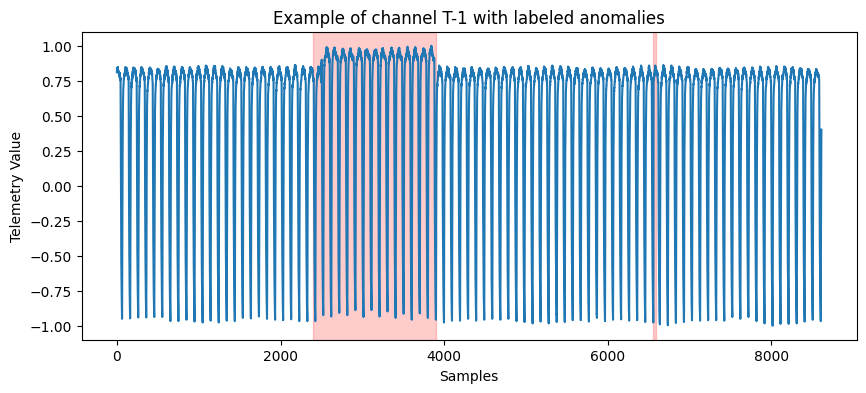

In [ ]:
# B1.6 Exploring an specific channel: telemetry values and anomalies

telemetry_values = c_signal[:,0]

fig,ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(telemetry_values)
for anom in anom_array:
    ax.axvspan(anom[0], anom[1], color='red', alpha=0.2)
ax.set_xlabel('Samples')
ax.set_ylabel('Telemetry Value')
ax.set_title(f'Example of channel {c_name} with labeled anomalies')
plt.show()

# Supervised Anomaly Detection

In supervised anomaly detection, machine learning models are trained using labeled examples of both nominal and anomalous behavior.
The objective is to learn decision boundaries that allow the model to distinguish between normal and anomalous patterns in unseen data.

In this section, we will:
- preprocess telemetry signals using sliding windows,
- generate window-level labels from anomaly intervals,
- extract features from each window,
- and train supervised classifiers to detect anomalous telemetry behavior.

This approach allows us to evaluate anomaly detection as a classification problem using labeled telemetry windows.

For this case we will use the original `test/` set, since it contains both nominal and anomalous telemetry behavior.

---------

## Step 2: Process the data to feed the ML model

### 2.1 Window-based preprocessing

Machine learning models usually require input samples with a fixed size. However, telemetry channels are long time series, often containing thousands of samples.

For example, a single SMAP channel may contain more than 7000 time samples. Instead of using the entire time series as one input sample, we divide it into smaller fixed-length segments called **windows**.

This allows us to transform a long telemetry signal into a dataset of multiple samples that can be used to train and evaluate machine learning models.

The windowing process is controlled by two main parameters:

- `window_size`: number of consecutive time samples included in each window.
- `stride`: number of samples used to move the window forward.

A smaller stride produces more overlapping windows, while a larger stride reduces the number of windows and the computational cost.

For the selected telemetry channel, we will apply sliding-window preprocessing to divide the time series into fixed-size windows.

Each window will contain `window_size` consecutive samples, and the starting point of each window will be separated by `stride` samples.

In [ ]:
# B2.0 Window based preprocessing for a single telemetry channel

window_size = 50
stride = 5


windows = []

for start in range(0, len(telemetry_values) - window_size + 1, stride):
    end = start + window_size
    window = telemetry_values[start:end]
    windows.append(window)

windows = np.array(windows)

print("Original signal shape:", telemetry_values.shape)
print("Windowed dataset shape:", windows.shape)

Original signal shape: (8612,)
Windowed dataset shape: (1713, 50)


If the original signal contains $N$ samples, the total number of generated windows is:

$\text{num\_windows} =\left\lfloor\frac{N - \text{window\_size}}{\text{stride}}\right\rfloor + 1$

After preprocessing, the original time series with shape $(N,)$ is transformed into a windowed dataset with shape $(\text{num\_windows}, \text{window\_size})$ where each row corresponds to one input sample for the machine learning model.

#### Things to consider for window-based processing:

1. `window_size`: How much temporal context should each sample contain?
   
Small windows:
  * More local information
  * Faster processing
  * May miss long anomalies

Large windows:
  * More temporal context
  * Better for long-duration events
  * Higher computational cost

2. `stride`: How much should the window move between consecutive samples?

Small stride:
  * More overlap
  * More training samples
  * Smoother temporal coverage

Large stride:
  * Fewer samples
  * Lower computational cost
  * Possible information loss


### 2.2 Window labeling

The original labels are defined per sample or anomaly interval but ML models operate on windows.

Original labels: anomaly from sample 2399 to 3898

But after windowing: each window needs ONE label

How should we label a window that contains both nominal and anomalous samples?
- Any anomalous sample = anomalous window
- Anomaly percentage threshold
- Majority voting

### 2.3 Preprocess the whole dataset

So far, we explored a single telemetry channel to better understand the structure of the data and the windowing process.

We now extend this preprocessing pipeline to all available SMAP channels.

The steps of this process are:
1. Load every telemetry channel
2. Apply sliding-window preprocessing
3. Generate window-level labels
4. Combine all windows into a single dataset matrix suitable for machine learning.

After preprocessing, the dataset will contain one row per window and one label per window indicating nominal or anomalous behavior.

This transforms the original collection of long telemetry time series into a structured dataset that can be directly used for supervised anomaly detection.

In [ ]:
import os
import ast
import numpy as np
import pandas as pd


class NASASupervisedLoader:

    def __init__(
        self,
        root_dir,
        spacecraft="SMAP",
        window_size=50,
        stride=5
    ):

        self.root_dir = root_dir
        self.spacecraft = spacecraft
        self.window_size = window_size
        self.stride = stride

        self.test_dir = os.path.join(
            root_dir,
            "data",
            "data",
            "test"
        )

        self.labels_df = pd.read_csv(
            os.path.join(
                root_dir,
                "labeled_anomalies.csv"
            )
        )

        self.labels_df = self.labels_df[
            self.labels_df["spacecraft"] == spacecraft
        ]

    def load_channel(self, channel_id):

        path = os.path.join(
            self.test_dir,
            f"{channel_id}.npy"
        )

        data = np.load(path)

        # Make sure data is 2D
        if data.ndim == 1:
            data = data.reshape(-1, 1)

        row = self.labels_df[
            self.labels_df["chan_id"] == channel_id
        ].iloc[0]

        anomaly_sequences = ast.literal_eval(
            row["anomaly_sequences"]
        )

        labels = np.zeros(len(data))

        for start, end in anomaly_sequences:
            labels[start:end + 1] = 1

        return data, labels

    def create_windows(self, data, labels):

        X = []
        y = []

        for i in range(
            0,
            len(data) - self.window_size + 1,
            self.stride
        ):

            window = data[
                i:i + self.window_size
            ]

            label_window = labels[
                i:i + self.window_size
            ]

            # Window is anomalous
            # if it contains at least one anomaly
            label = int(np.any(label_window))

            X.append(window)
            y.append(label)

        return np.array(X), np.array(y)

    def extract_features(self, X):
        mean = np.mean(X, axis=1)
        std = np.std(X, axis=1)
        minimum = np.min(X, axis=1)
        maximum = np.max(X, axis=1)
        median = np.median(X, axis=1)
        signal_range = maximum - minimum
        q25 = np.percentile(X, 25, axis=1)
        q75 = np.percentile(X, 75, axis=1)
        iqr = q75 - q25
        rms = np.sqrt(np.mean(X ** 2, axis=1))
        t = np.arange(X.shape[1])
        t_centered = t - np.mean(t) 
        slope = (
            np.sum(
                t_centered[None, :, None]
                * (X - mean[:, None, :]),
                axis=1
            )
            / np.sum(t_centered ** 2)
        )
    
        differences = np.diff(X, axis=1)
        mean_abs_diff = np.mean(
            np.abs(differences),
            axis=1
        )
    
        # Combine all features
        features = np.concatenate(
            [
                mean,
                std,
                minimum,
                maximum,
                median,
                signal_range,
                iqr,
                rms,
                slope,
                mean_abs_diff
            ],
            axis=1
        )

        return features

    def load_all(self):

        X_all = []
        y_all = []

        channels = self.labels_df["chan_id"].values

        for channel_id in channels:

            print(f"Loading {channel_id}")

            data, labels = self.load_channel(
                channel_id
            )

            X, y = self.create_windows(
                data,
                labels
            )

            X_all.append(X)
            y_all.append(y)

        X_all = np.concatenate(
            X_all,
            axis=0
        )

        y_all = np.concatenate(
            y_all,
            axis=0
        )

        # into 100 statistical features

        X_features = self.extract_features(X_all)
        return X_features, y_all

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


loader = NASASupervisedLoader(
    root_dir="/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl",
    spacecraft="SMAP",
    window_size=100,
    stride=5
)

X, y = loader.load_all()

print("Shape of dataset:", X.shape)
print("Shape of labels:", y.shape)

print("Nominal:", np.sum(y == 0))
print("Anomaly:", np.sum(y == 1))

Loading P-1
Loading S-1
Loading E-1
Loading E-2
Loading E-3
Loading E-4
Loading E-5
Loading E-6
Loading E-7
Loading E-8
Loading E-9
Loading E-10
Loading E-11
Loading E-12
Loading E-13
Loading A-1
Loading D-1
Loading P-2
Loading P-3
Loading D-2
Loading D-3
Loading D-4
Loading A-2
Loading A-3
Loading A-4
Loading G-1
Loading G-2
Loading D-5
Loading D-6
Loading D-7
Loading F-1
Loading P-4
Loading G-3
Loading T-1
Loading T-2
Loading D-8
Loading D-9
Loading F-2
Loading G-4
Loading T-3
Loading D-11
Loading D-12
Loading B-1
Loading G-6
Loading G-7
Loading P-7
Loading R-1
Loading A-5
Loading A-6
Loading A-7
Loading D-13
Loading P-2
Loading A-8
Loading A-9
Loading F-3
Shape of dataset: (87739, 250)
Shape of labels: (87739,)
Nominal: 75165
Anomaly: 12574


### 2.4 Train-test split

Once all telemetry windows have been generated and combined into a single dataset, we divide the data into training and testing subsets.

The training set is used to learn the patterns associated with nominal and anomalous telemetry behavior, while the test set is used to evaluate the model performance on unseen windows.

This separation is essential to assess how well the model generalizes to new telemetry data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [ ]:
print("X_train:",  X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (70191, 250)
X_test: (17548, 250)
y_train: (70191,)
y_test: (17548,)


## Step 3. Training the ML models

After preprocessing the telemetry data and generating window-level labels, we can now train machine learning models for anomaly detection.
In this example, anomaly detection is formulated as a supervised classification problem, where the objective is to distinguish between nominal and anomalous telemetry windows.

A wide range of supervised machine learning methods can be applied to this task, from classical machine learning algorithms to deep learning approaches. Examples include:
- Random Forest,
- XGB Boost,

### 3.1 Random Forest

Random Forest is an ensemble learning method that combines multiple decision trees to improve robustness and predictive performance. Each tree is trained using different subsets of the data and features, and the final prediction is obtained through majority voting.

In [ ]:
# B3.1 Build and train a Random Forest Classifier model 

from sklearn.ensemble import RandomForestClassifier

clf_rf = RandomForestClassifier(
   n_estimators=500,
    min_samples_split=3,
    min_samples_leaf=1,
    max_features=0.8,
    max_depth=20,
    bootstrap=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

clf_rf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', max_depth=20, max_features=0.8,
                       min_samples_split=3, n_estimators=500, n_jobs=-1,
                       random_state=42)

In [ ]:
from xgboost import XGBClassifier

clf_xgb = XGBClassifier(
subsample= np.float64(0.7975963276978075),
  reg_lambda= np.float64(1.5468833388489516),
  reg_alpha= np.float64(0.013936287708201545),
  n_estimators= np.int64(915),
  min_child_weight= np.int64(1),
  max_depth= np.int64(9),
  learning_rate= np.float64(0.08067373048451444),
  gamma= np.float64(0.31713889282271535),
  colsample_bytree= np.float64(0.8688960372159247),
     random_state=42,
    n_jobs=-1

)

clf_xgb.fit(X_train, y_train)



XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.8688960372159247), device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric=None, feature_types=None, feature_weights=None,
              gamma=np.float64(0.31713889282271535), grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=np.float64(0.08067373048451444), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=np.int64(9), max_leaves=None,
              min_child_weight=np.int64(1), missing=nan,
              monotone_constraints=None, multi_strategy=None,
              n_estimators=np.int64(915), n_jobs=-1, num_parallel_tree=None, ...)

### 3.1.1 Evaluation of the model performance: Confusion matrix 
The confusion matrix provides a detailed view of the model predictions.

It shows:
- correctly detected nominal windows (`True Negatives`),
- false alarms (`False Positives`),
- missed anomalies (`False Negatives`),
- and correctly detected anomalous windows (`True Positives`).

In telemetry anomaly detection, both false alarms and missed anomalies are important:
- excessive false alarms can overwhelm operators,
- while missed anomalies may hide critical system behaviors.

The confusion matrix helps us better understand these trade-offs before analyzing the classification metrics.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay,recall_score,f1_score,precision_score
def Evaluate_Model(y_true,y_preds):
    print(f"recall score:{recall_score(y_true,y_preds)}")
    print(f"precison score:{precision_score(y_true,y_preds)}")
    print(f"f1 score:{f1_score(y_true,y_preds)}")
    ConfusionMatrixDisplay.from_predictions(y_true,y_preds)

## Random Forest Evaluation

recall score:0.9662988368625112
precison score:0.9340764943301941
f1 score:0.9499144881505008


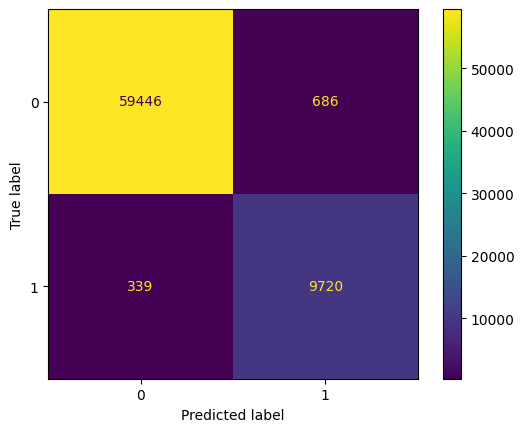

In [ ]:
y_train_preds=clf_rf.predict( X_train)
Evaluate_Model(y_train,y_train_preds)

recall score:0.9001988071570577
precison score:0.9052379048380648
f1 score:0.9027113237639554


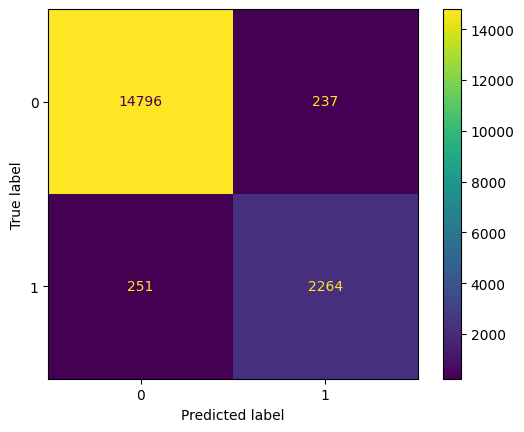

In [ ]:
preds = clf_rf.predict(X_test)
Evaluate_Model(y_test,preds)

In [ ]:
probs = clf_rf.predict_proba(X_test)[:, 1]

preds = (probs >= 0.30).astype(int)
for threshold in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    preds = (probs >= threshold).astype(int)

    print(
        threshold,
        "Precision:", precision_score(y_test, preds),
        "Recall:", recall_score(y_test, preds),
        "F1:", f1_score(y_test, preds)
    )

0.1 Precision: 0.46883314329152415 Recall: 0.9809145129224652 F1: 0.6344348720586345
0.15 Precision: 0.6502423263327949 Recall: 0.9602385685884692 F1: 0.775405362016375
0.2 Precision: 0.6659267480577137 Recall: 0.9542743538767395 F1: 0.784441902271613
0.25 Precision: 0.6774193548387096 Recall: 0.9518886679920477 F1: 0.7915357910398413
0.3 Precision: 0.8460421205519245 Recall: 0.9264413518886679 F1: 0.8844182956917821
0.35 Precision: 0.8607500928332714 Recall: 0.9216699801192842 F1: 0.8901689708141322
0.4 Precision: 0.8760456273764259 Recall: 0.91610337972167 F1: 0.8956268221574344
0.45 Precision: 0.8934586760673717 Recall: 0.9069582504970178 F1: 0.9001578531965272
0.5 Precision: 0.9052379048380648 Recall: 0.9001988071570577 F1: 0.9027113237639554


## XGB boost Evaluation Metrics

recall score:0.953375086986778
precison score:0.9986462563782151
f1 score:0.975485708473197


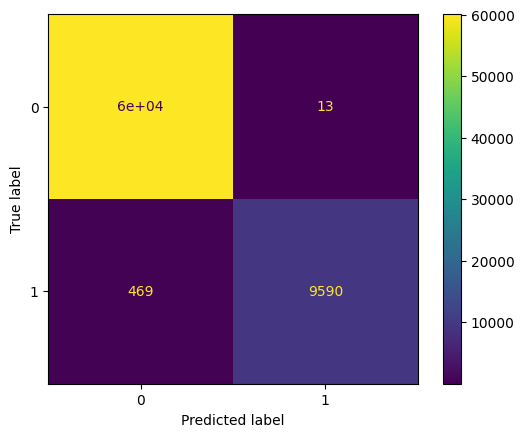

In [ ]:
y_train_preds=clf_xgb.predict( X_train)
Evaluate_Model(y_train,y_train_preds)

recall score:0.868389662027833
precison score:0.9702354509107064
f1 score:0.9164918170373478


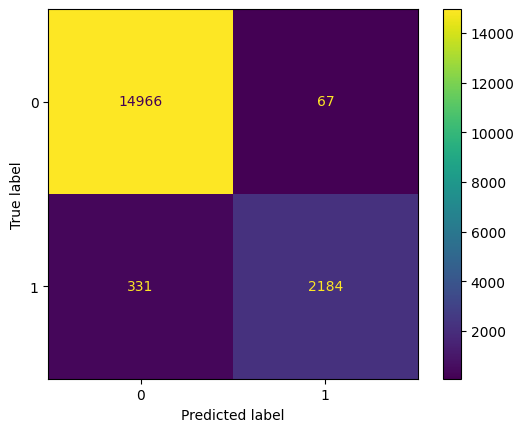

In [ ]:
preds = clf_xgb.predict(X_test)
Evaluate_Model(y_test,preds)

In [ ]:
probs = clf_xgb.predict_proba(X_test)[:, 1]

preds = (probs >= 0.30).astype(int)
for threshold in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    preds = (probs >= threshold).astype(int)

    print(
        threshold,
        "Precision:", precision_score(y_test, preds),
        "Recall:", recall_score(y_test, preds),
        "F1:", f1_score(y_test, preds)
    )

0.1 Precision: 0.8396533044420368 Recall: 0.9244532803180915 F1: 0.8800151400454201
0.15 Precision: 0.883935434281322 Recall: 0.9145129224652088 F1: 0.8989642368575337
0.2 Precision: 0.9084030266825965 Recall: 0.9069582504970178 F1: 0.9076800636689216
0.25 Precision: 0.9227642276422764 Recall: 0.9025844930417495 F1: 0.9125628140703518
0.3 Precision: 0.9358065860775323 Recall: 0.8926441351888668 F1: 0.9137159137159138
0.35 Precision: 0.9468763280917977 Recall: 0.8858846918489066 F1: 0.9153656532456861
0.4 Precision: 0.9576490924805532 Recall: 0.8811133200795228 F1: 0.9177883619797059
0.45 Precision: 0.9645514223194749 Recall: 0.8763419483101391 F1: 0.9183333333333333
0.5 Precision: 0.9702354509107064 Recall: 0.868389662027833 F1: 0.9164918170373478


In [ ]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=700,
    max_samples=0.8,
    contamination=0.1356,
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train)

IsolationForest(contamination=0.1356, max_samples=0.8, n_estimators=700,
                n_jobs=-1, random_state=42)

In [ ]:
preds =[1 if i==-1  else 0 for i in model.predict(X_test) ]

recall score:0.10099403578528827
precison score:0.10614291684078563
f1 score:0.10350448247758762


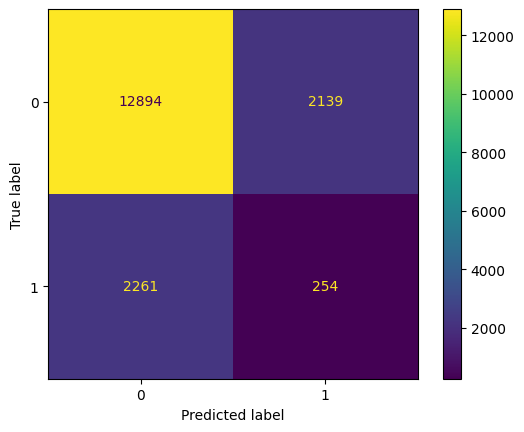

In [ ]:
Evaluate_Model(y_test,preds)

# Creating a Pipline and save the model

In [ ]:
import os
import ast
import numpy as np
import pandas as pd


class NASASupervisedLoader:

    def __init__(
        self,
        root_dir,
        spacecraft="SMAP",
        window_size=50,
        stride=5
    ):

        self.root_dir = root_dir
        self.spacecraft = spacecraft
        self.window_size = window_size
        self.stride = stride

        self.test_dir = os.path.join(
            root_dir,
            "data",
            "data",
            "test"
        )

        self.labels_df = pd.read_csv(
            os.path.join(
                root_dir,
                "labeled_anomalies.csv"
            )
        )

        self.labels_df = self.labels_df[
            self.labels_df["spacecraft"] == spacecraft
        ]

    def load_channel(self, channel_id):

        path = os.path.join(
            self.test_dir,
            f"{channel_id}.npy"
        )

        data = np.load(path)

        # Make sure data is 2D
        if data.ndim == 1:
            data = data.reshape(-1, 1)

        row = self.labels_df[
            self.labels_df["chan_id"] == channel_id
        ].iloc[0]

        anomaly_sequences = ast.literal_eval(
            row["anomaly_sequences"]
        )

        labels = np.zeros(len(data))

        for start, end in anomaly_sequences:
            labels[start:end + 1] = 1

        return data, labels

    def create_windows(self, data, labels):

        X = []
        y = []

        for i in range(
            0,
            len(data) - self.window_size + 1,
            self.stride
        ):

            window = data[
                i:i + self.window_size
            ]

            label_window = labels[
                i:i + self.window_size
            ]

            # Window is anomalous
            # if it contains at least one anomaly
            label = int(np.any(label_window))

            X.append(window)
            y.append(label)

        return np.array(X), np.array(y)

   
    def load_all(self):

        X_all = []
        y_all = []

        channels = self.labels_df["chan_id"].values

        for channel_id in channels:

            print(f"Loading {channel_id}")

            data, labels = self.load_channel(
                channel_id
            )

            X, y = self.create_windows(
                data,
                labels
            )

            X_all.append(X)
            y_all.append(y)

        X_all = np.concatenate(
            X_all,
            axis=0
        )

        y_all = np.concatenate(
            y_all,
            axis=0
        )

    
        return X_all, y_all

In [ ]:

import joblib

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
class StatisticalFeatureExtractor(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        mean = np.mean(X, axis=1)
        std = np.std(X, axis=1)
        minimum = np.min(X, axis=1)
        maximum = np.max(X, axis=1)
        median = np.median(X, axis=1)
        signal_range = maximum - minimum
        q25 = np.percentile(X, 25, axis=1)
        q75 = np.percentile(X, 75, axis=1)
        iqr = q75 - q25
        rms = np.sqrt(np.mean(X ** 2, axis=1))
        t = np.arange(X.shape[1])
        t_centered = t - np.mean(t)
        slope = (
            np.sum(
                t_centered[None, :, None]
                * (X - mean[:, None, :]),
                axis=1
            )
            / np.sum(t_centered ** 2)
        )
        
        differences = np.diff(X, axis=1)

        mean_abs_diff = np.mean(
            np.abs(differences),
            axis=1
        )

        return np.concatenate(
            [
                mean,
                std,
                minimum,
                maximum,
                median,
                signal_range,
                iqr,
                rms,
                slope,
                mean_abs_diff
            ],
            axis=1
        )



class ThresholdClassifier(BaseEstimator, ClassifierMixin):

    def __init__(self, model, threshold=0.45):
        self.model = model
        self.threshold = threshold

    def fit(self, X, y):
        self.model.fit(X, y)
        self.classes_ = self.model.classes_
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        probabilities = self.model.predict_proba(X)[:, 1]
        return (probabilities >= self.threshold).astype(int)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


loader = NASASupervisedLoader(
    root_dir="/kaggle/input/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl",
    spacecraft="SMAP",
    window_size=100,
    stride=5
)

X, y = loader.load_all()

print("Shape of dataset:", X.shape)
print("Shape of labels:", y.shape)

print("Nominal:", np.sum(y == 0))
print("Anomaly:", np.sum(y == 1))

Loading P-1
Loading S-1
Loading E-1
Loading E-2
Loading E-3
Loading E-4
Loading E-5
Loading E-6
Loading E-7
Loading E-8
Loading E-9
Loading E-10
Loading E-11
Loading E-12
Loading E-13
Loading A-1
Loading D-1
Loading P-2
Loading P-3
Loading D-2
Loading D-3
Loading D-4
Loading A-2
Loading A-3
Loading A-4
Loading G-1
Loading G-2
Loading D-5
Loading D-6
Loading D-7
Loading F-1
Loading P-4
Loading G-3
Loading T-1
Loading T-2
Loading D-8
Loading D-9
Loading F-2
Loading G-4
Loading T-3
Loading D-11
Loading D-12
Loading B-1
Loading G-6
Loading G-7
Loading P-7
Loading R-1
Loading A-5
Loading A-6
Loading A-7
Loading D-13
Loading P-2
Loading A-8
Loading A-9
Loading F-3
Shape of dataset: (87739, 100, 25)
Shape of labels: (87739,)
Nominal: 75165
Anomaly: 12574


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
xgb_pipeline = Pipeline([
    ("features", StatisticalFeatureExtractor()),
    ("scaler", StandardScaler()),
    ("model", ThresholdClassifier(
        model=clf_xgb,
        threshold=0.45
    ))
])

In [ ]:
xgb_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('features', StatisticalFeatureExtractor()),
                ('scaler', StandardScaler()),
                ('model',
                 ThresholdClassifier(model=XGBClassifier(base_score=None,
                                                         booster=None,
                                                         callbacks=None,
                                                         colsample_bylevel=None,
                                                         colsample_bynode=None,
                                                         colsample_bytree=np.float64(0.8688960372159247),
                                                         device=None,
                                                         early_stopping_rounds=None,
                                                         enable_categorical=True,
                                                         eval_metric=No...
                                                         importance_type=None,
                                                         interaction_constraints=None,
                                                         learning_rate=np.float64(0.08067373048451444),
                                                         max_bin=None,
                                                         max_cat_threshold=None,
                                                         max_cat_to_onehot=None,
                                                         max_delta_step=None,
                                                         max_depth=np.int64(9),
                                                         max_leaves=None,
                                                         min_child_weight=np.int64(1),
                                                         missing=nan,
                                                         monotone_constraints=None,
                                                         multi_strategy=None,
                                                         n_estimators=np.int64(915),
                                                         n_jobs=-1,
                                                         num_parallel_tree=None, ...)))])

recall score:0.8763419483101391
precison score:0.9645514223194749
f1 score:0.9183333333333333


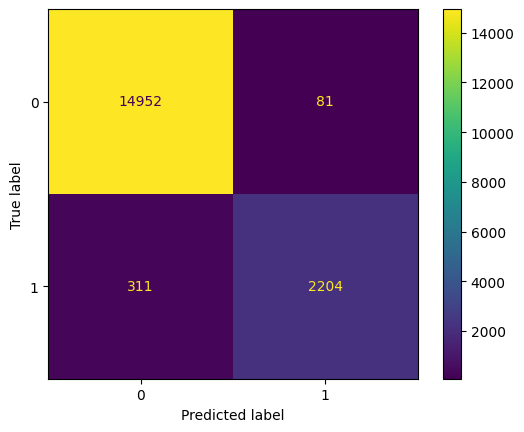

In [ ]:
preds = xgb_pipeline.predict(X_test)
Evaluate_Model(y_test,preds)

In [ ]:
import joblib

joblib.dump(
    xgb_pipeline,
    "NASA_SMAP_XGBoost_pipeline.pkl"
)

print("Pipeline saved successfully.")

Pipeline saved successfully.
